# a fast model of the ray tracer

## why

every number so far came from the ray tracer: trace a thousand rays, at three angles, through two surfaces, then try 241 sensor positions. that's exact, but each lens takes a few milliseconds, and a real design search can mean millions of lenses, many more knobs and many more surfaces.

a **surrogate model** is a machine learning model that learns to predict the ray tracer's answer, so it can skip the tracing. it learns from examples: show it a thousand lenses along with their true blur, and it learns the pattern. then it can guess the blur of a new lens almost instantly. the ray tracer is still the ground truth: the model is only used to find promising designs quickly, and the best ones get checked by the real tracer.

## the idea, step by step

**1. inputs and output.** the model gets the three knobs from the whole-field notebook (08):

- **R1**: the front radius (mm), from 25 to 300. R2 is calculated with R2_for, so f stays 50 mm.
- **t**: the thickness (mm), from 3 to 8.
- **z_stop**: where the aperture stop sits (mm), from −20 (in front of the lens) to 0 (at the lens).

in machine learning these inputs are called **features** (written X). the output to predict is the **target** (written y): here, the **field loss**, the average spot over 0°, 5° and 10° on the best compromise sensor, at f/5. the same number best_field gives.

**2. a dataset.** pick 1000 random lenses (random R1, t and z_stop), and run the real ray tracer on each to get its field loss. each lens is one row: three features and one target. this is the only slow step.

**3. train and test.** split the 1000 lenses: the model learns from 800 (the **training set**) and is graded on the other 200 (the **test set**), which it never sees while learning. a model can look great on examples it has memorized; the test set shows how it does on lenses it has never seen, which is the only thing that matters.

**4. two models.**

- **linear regression**: the simplest model. it assumes the loss is a straight-line mix of the inputs, loss ≈ w1 × R1 + w2 × t + w3 × z_stop + b, and finds the four numbers (w1, w2, w3, b) that fit the training lenses best. it's the baseline: if it's good enough, nothing fancier is needed.
- **random forest**: a forest of 200 **decision trees**. each tree predicts by asking a chain of yes/no questions about the inputs ("is z_stop below −12? is R1 above 80?") and answering with the average loss of the training lenses that ended up in the same place. each tree learns from a slightly different random sample, so each makes different mistakes, and the forest's answer is the average of all 200, which cancels much of the error. trees can follow curves and interactions that a straight line can't.

**5. measuring the error.**

- **MAE** (mean absolute error): on average, how far the prediction is from the true loss, in mm.
- **percentage error**: the same, as a percent of the true loss.
- **R²**: how much of the variation between lenses the model explains. 1 is perfect, 0 is no better than always guessing the average.

**6. using it.** ask the model about 100,000 random lenses (fast), pick the ones it thinks are best, and check those with the real ray tracer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import sys
sys.path.append("..")
from lens.raytrace import best_field
from lens.design import R2_for
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [2]:
rng = np.random.default_rng(42)
X = []
y = []
start = time.time()
for i in range(1000):
    R1 = rng.uniform(25, 300)
    t = rng.uniform(3, 8)
    z_stop = rng.uniform(-20, 0)
    lens = [(0, R1, 1.5), (t, R2_for(R1, t, 50), 1.0)]
    z_sensor, loss = best_field(lens, z_stop)
    X.append([R1, t, z_stop])
    y.append(loss)
seconds = time.time() - start
X = np.array(X)
y = np.array(y)

print(X.shape, y.shape)
print(f"{seconds:.1f} s for 1000 lenses, {seconds:.1f} ms per lens")
print(f"field loss from {y.min():.4f} to {y.max():.4f} mm")

(1000, 3) (1000,)
11.7 s for 1000 lenses, 11.7 ms per lens
field loss from 0.0292 to 0.0840 mm


**the dataset.** 1000 random lenses, each traced for real: X has 1000 rows and 3 columns (R1, t, z_stop), y has 1000 field losses. rng.uniform(a, b) picks a random number anywhere between a and b, all equally likely (unlike rng.normal, which bunches up around the mean). the losses range from about 0.029 mm (the best lenses) to 0.084 mm (the worst).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
print(X_train.shape, X_test.shape)

(800, 3) (200, 3)


**train and test.** train_test_split shuffles the lenses and keeps 20% (test_size = 0.2) aside: 800 to learn from, 200 to grade on. random_state = 42 is its seed, so the split is the same every run.

In [4]:
linear = LinearRegression()
linear.fit(X_train, y_train)
pred_linear = linear.predict(X_test)

print("weights:", linear.coef_, "intercept:", linear.intercept_)
print(f"MAE {mean_absolute_error(y_test, pred_linear):.5f} mm")
print(f"error {np.mean(np.abs(pred_linear - y_test) / y_test) * 100:.1f}%")
print(f"R² {r2_score(y_test, pred_linear):.3f}")

weights: [ 3.74575070e-06 -1.02092625e-03  1.69133483e-03] intercept: 0.06568931585287732
MAE 0.00542 mm
error 12.7%
R² 0.693


**linear regression.** .fit learns the weights from the training lenses; .predict uses them on the test lenses. it's off by about 13% on average and explains about 69% of the variation (R² 0.69). the weights say the general trend (a stop further in front lowers the loss), but a straight line can't capture the real shape: the best lenses sit in a valley (R1 around 100 mm, stop around −15 mm), and a straight line has no valleys.

In [5]:
forest = RandomForestRegressor(n_estimators = 200, random_state = 42)
forest.fit(X_train, y_train)
pred_forest = forest.predict(X_test)

print(f"MAE {mean_absolute_error(y_test, pred_forest):.5f} mm")
print(f"error {np.mean(np.abs(pred_forest - y_test) / y_test) * 100:.1f}%")
print(f"R² {r2_score(y_test, pred_forest):.3f}")
print("importance of R1, t, z_stop:", forest.feature_importances_)

MAE 0.00081 mm
error 1.8%
R² 0.992
importance of R1, t, z_stop: [0.13615799 0.03588148 0.82796053]


**random forest.** 200 trees (n_estimators = 200), with the same fit and predict as before. it's off by under 2% on average on lenses it has never seen, and explains over 99% of the variation. **feature importance** is how much each input helped the trees' questions: the stop position matters most (about 83%), then R1 (about 14%), while thickness barely matters (about 4%). that matches the physics from notebook 08: the stop and the bending set the field curvature, and thickness hardly changes it.

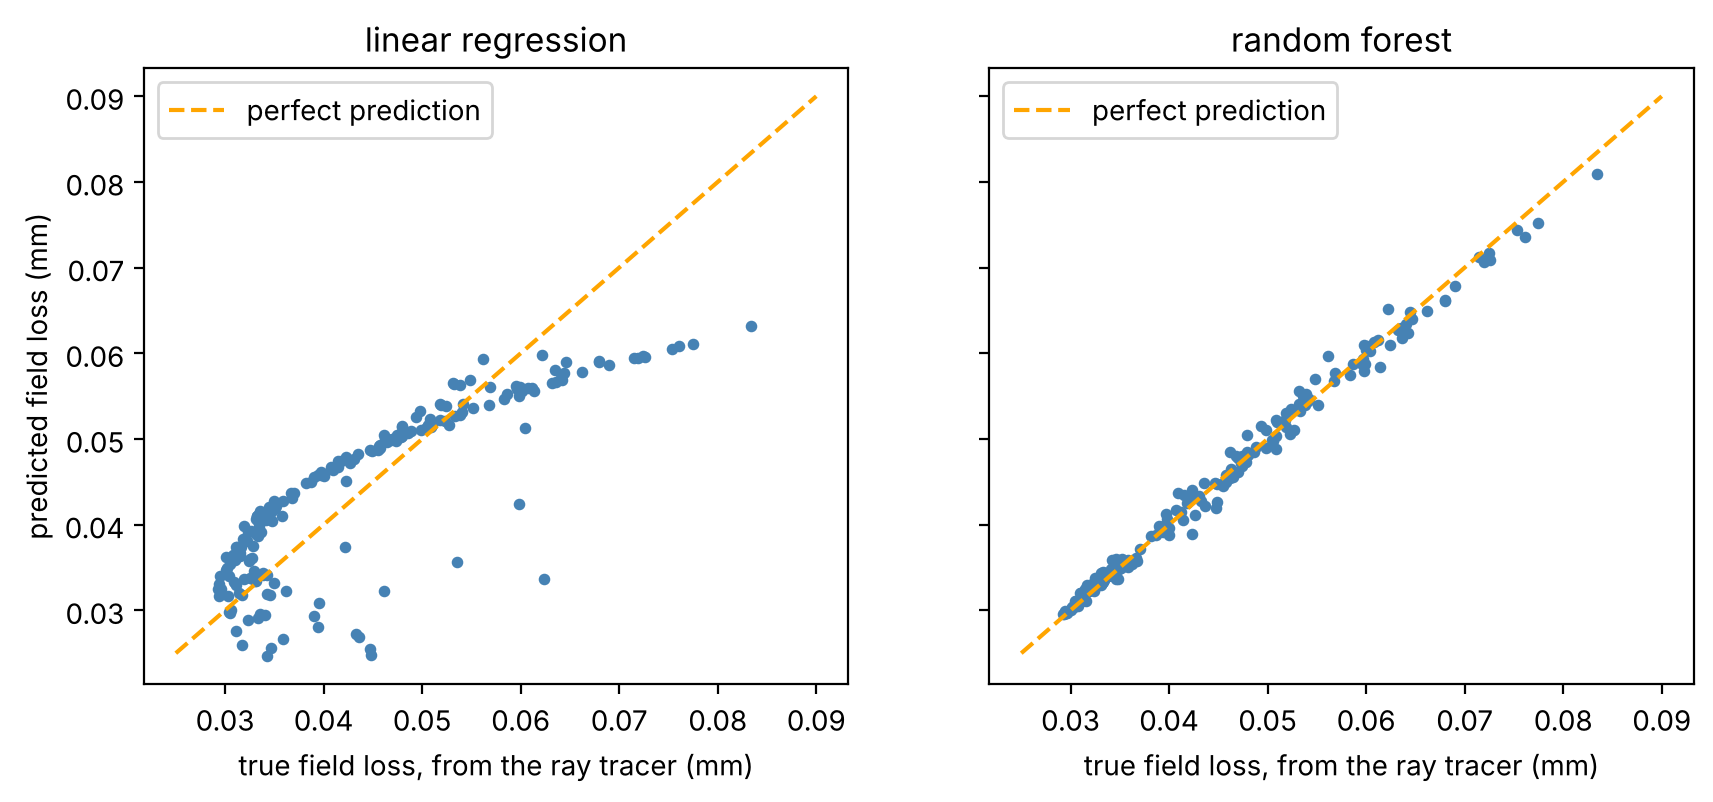

In [6]:
fig, axes = plt.subplots(1, 2, figsize = (10, 4), sharey = True)
for ax, pred, name in [(axes[0], pred_linear, "linear regression"), (axes[1], pred_forest, "random forest")]:
    ax.scatter(y_test, pred, s = 10, color = "steelblue")
    ax.plot([0.025, 0.09], [0.025, 0.09], ls = "--", color = "orange", label = "perfect prediction")
    ax.set_title(name)
    ax.set_xlabel("true field loss, from the ray tracer (mm)")
    ax.legend()
axes[0].set_ylabel("predicted field loss (mm)")
plt.show()

**predicted vs true**, for the 200 test lenses. each dot is one lens; a perfect model puts every dot on the orange line. the linear model's dots bend away from it: it guesses too high for the best lenses and too low for the worst, because the real pattern is curved and a straight line can't follow it. the forest's dots sit almost on the line. plt.subplots(1, 2) makes two plots side by side, and sharey = True gives them the same y axis so they can be compared.

In [7]:
start = time.time()
for i in range(100):
    lens = [(0, X_test[i, 0], 1.5), (X_test[i, 1], R2_for(X_test[i, 0], X_test[i, 1], 50), 1.0)]
    best_field(lens, X_test[i, 2])
tracer_each = (time.time() - start) / 100

candidates = np.column_stack([rng.uniform(25, 300, 100000), rng.uniform(3, 8, 100000), rng.uniform(-20, 0, 100000)])
start = time.time()
predicted = forest.predict(candidates)
model_each = (time.time() - start) / 100000

print(f"ray tracer: {tracer_each * 1000:.2f} ms per lens")
print(f"forest:     {model_each * 1000:.4f} ms per lens")
print(f"about {tracer_each / model_each:.0f}x faster")

ray tracer: 11.96 ms per lens
forest:     0.0168 ms per lens
about 712x faster


**speed.** the ray tracer takes a few milliseconds per lens; the forest predicts 100,000 lenses at once at a few microseconds each, hundreds of times faster. (exact timings depend on the computer.) np.column_stack glues three columns of 100,000 random numbers side by side into one table of candidates.

In [8]:
order = np.argsort(predicted)
print("R1      t     z_stop   predicted   ray tracer")
for i in order[:5]:
    R1, t, z_stop = candidates[i]
    lens = [(0, R1, 1.5), (t, R2_for(R1, t, 50), 1.0)]
    z_sensor, true_loss = best_field(lens, z_stop)
    print(f"{R1:6.1f}  {t:4.2f}  {z_stop:6.2f}   {predicted[i]:.5f}     {true_loss:.5f}")

R1      t     z_stop   predicted   ray tracer
  86.6  7.81  -15.71   0.02941     0.02926
  87.7  7.86  -15.61   0.02942     0.02924
 101.7  7.87  -15.06   0.02942     0.02933
  85.9  7.88  -15.73   0.02942     0.02928
  89.1  7.81  -15.95   0.02943     0.02940


**searching with the model.** np.argsort gives the positions that would sort the predictions from smallest to largest, so order[:5] are the five candidates the model thinks are best. each one is then checked with the real ray tracer.

all five land in the same place: R1 around 85 to 100 mm and the stop about 15 mm in front of the lens. that's the same region the grid search found in the whole-field notebook (08) (R1 = 100 mm, stop at −15 mm), found here without anyone telling the model where to look. the ray tracer confirms them at 0.029 mm, as good as the grid search's 0.0295 mm. thickness is mostly near the top of its range, but as the importance showed, it changes very little.

**one limit to know:** a random forest answers with averages of training lenses, so it can never predict a loss lower than the best one it was trained on. it's good for finding the right region fast, but the final numbers must always come from the ray tracer.

## what this shows

- a random forest trained on 800 traced lenses predicts the blur of new lenses within about 2%, hundreds of times faster than tracing them.
- a straight-line model isn't enough here (13% error): the design space has a valley, and finding valleys needs a model that can bend.
- the model independently finds the best region the grid search found, and the ray tracer confirms it.
- in a real lens with many surfaces and knobs, a grid search becomes impossible (10 values for each of 10 knobs is 10 billion lenses). that's where a fast surrogate earns its place: screen millions of designs with the model, then trace only the best few.